# Question 1 – Data Preparation, Leakage, and Experimental Design

Dataset: **Bank Marketing** (UCI, `bank-additional-full.csv`). Binary target `y`: did the client subscribe to a term deposit?

The fixed split built here (`src/split.py`, seed in `src/config.py`) is reused unchanged in Q2, Q4 and Q5.
The **test partition is never used in this notebook** except to report its size and class proportions.

In [1]:
# --- Setup: works both in Google Colab and locally -------------------------
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/alialp5959/Ceng463_TakeHomeMidterm.git"
BRANCH = "claude/gallant-ptolemy-7vwlyn"   # change to "main" after merging

if "google.colab" in sys.modules:
    ROOT = Path("/content/Ceng463_TakeHomeMidterm")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(ROOT)], check=True)
else:
    ROOT = Path.cwd()
    if ROOT.name == "notebooks":
        ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from src.config import SEED, FIGURES, TABLES
from src.data import (load_bank_raw, clean_bank, bank_xy, TARGET,
                      BANK_NUMERIC, BANK_CATEGORICAL, BANK_BINARY_DERIVED, LEAKY_FEATURE)
from src.split import train_val_test_split, TEST_SIZE, VAL_SIZE
from src.preprocessing import make_bank_preprocessor

FIGURES.mkdir(parents=True, exist_ok=True); TABLES.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")

def save_table(df, name, index=True, float_format="%.4f"):
    df.to_csv(TABLES / f"{name}.csv", index=index)
    with open(TABLES / f"{name}.tex", "w") as f:
        f.write(df.to_latex(index=index, float_format=float_format.__mod__, escape=True))

def save_fig(fig, name):
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| seed", SEED)
print(platform.platform(), "|", os.cpu_count(), "CPU cores")

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | seed 42
Linux-6.18.44-fc-v230-x86_64-with-glibc2.39 | 4 CPU cores


## 1(a) Dataset description and audit

Audit on the **raw** file (before any cleaning), so the problems found here are the ones the pipeline must handle.

In [2]:
raw = load_bank_raw()
print("Shape:", raw.shape)
print("\nClass distribution:")
cls = raw[TARGET].value_counts().to_frame("count")
cls["percent"] = 100 * cls["count"] / len(raw)
display(cls)
print("\nColumn types:")
display(raw.dtypes.value_counts().rename("n_columns").to_frame())

Shape: (41188, 21)

Class distribution:


,count,percent
y,,
no,36548,88.734583
yes,4640,11.265417



Column types:


,n_columns
str,11
int64,5
float64,5


In [3]:
# Per-column audit table
num_raw = raw.select_dtypes("number").columns.tolist()
rows = []
for c in raw.columns:
    s = raw[c]
    is_num = c in num_raw
    n_unknown = int((s == "unknown").sum()) if not is_num else 0
    row = {
        "column": c,
        "type": "numeric" if is_num else ("target" if c == TARGET else "categorical"),
        "n_unique": s.nunique(),
        "n_NaN": int(s.isna().sum()),
        "n_unknown": n_unknown,
        "pct_unknown": 100 * n_unknown / len(s),
    }
    if is_num:
        q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
        row.update(min=s.min(), median=s.median(), max=s.max(),
                   n_IQR_outliers=int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()))
    else:
        vc = s.value_counts()
        row.update(most_frequent=f"{vc.index[0]} ({100*vc.iloc[0]/len(s):.1f}%)",
                   rarest=f"{vc.index[-1]} ({vc.iloc[-1]})")
    rows.append(row)
audit = pd.DataFrame(rows).set_index("column")
display(audit)

,type,n_unique,n_NaN,n_unknown,pct_unknown,min,median,max,n_IQR_outliers,most_frequent,rarest
column,,,,,,,,,,,
age,numeric,78,0,0,0.000000,17.000,38.000,98.000,469.0,NaN,NaN
job,categorical,12,0,330,0.801204,NaN,NaN,NaN,NaN,admin. (25.3%),unknown (330)
marital,categorical,4,0,80,0.194231,NaN,NaN,NaN,NaN,married (60.5%),unknown (80)
education,categorical,8,0,1731,4.202680,NaN,NaN,NaN,NaN,university.degree (29.5%),illiterate (18)
default,categorical,3,0,8597,20.872584,NaN,NaN,NaN,NaN,no (79.1%),yes (3)
housing,categorical,3,0,990,2.403613,NaN,NaN,NaN,NaN,yes (52.4%),unknown (990)
loan,categorical,3,0,990,2.403613,NaN,NaN,NaN,NaN,no (82.4%),unknown (990)
contact,categorical,2,0,0,0.000000,NaN,NaN,NaN,NaN,cellular (63.5%),telephone (15044)
month,categorical,10,0,0,0.000000,NaN,NaN,NaN,NaN,may (33.4%),dec (182)


In [4]:
# Duplicates
n_dup = int(raw.duplicated().sum())
feat_cols = [c for c in raw.columns if c != TARGET]
dup_feat = raw[raw.duplicated(subset=feat_cols, keep=False)]
conflicting = dup_feat.groupby(feat_cols, dropna=False)[TARGET].nunique()
print(f"Exact duplicate rows (all columns): {n_dup}")
print(f"Rows whose features repeat another row: {len(dup_feat)}")
print(f"Feature-duplicate groups with conflicting labels: {int((conflicting > 1).sum())}")

Exact duplicate rows (all columns): 12
Rows whose features repeat another row: 24
Feature-duplicate groups with conflicting labels: 0


In [5]:
# Anomalous / sentinel values and problematic predictors
checks = {}
checks["pdays == 999 (sentinel: never contacted)"] = int((raw.pdays == 999).sum())
checks["pdays == 999 but poutcome != 'nonexistent'"] = int(((raw.pdays == 999) & (raw.poutcome != "nonexistent")).sum())
checks["previous == 0 but poutcome != 'nonexistent'"] = int(((raw.previous == 0) & (raw.poutcome != "nonexistent")).sum())
checks["duration == 0"] = int((raw.duration == 0).sum())
checks["duration == 0 and y == 'yes'"] = int(((raw.duration == 0) & (raw.y == "yes")).sum())
checks["campaign > 20 calls"] = int((raw.campaign > 20).sum())
checks["age >= 90"] = int((raw.age >= 90).sum())
checks["default == 'yes'"] = int((raw.default == "yes").sum())
checks["housing and loan both 'unknown' (same rows)"] = int(((raw.housing == "unknown") & (raw.loan == "unknown")).sum())
anomalies = pd.Series(checks, name="count").to_frame()
display(anomalies)

,count
pdays == 999 (sentinel: never contacted),39673
pdays == 999 but poutcome != 'nonexistent',4110
previous == 0 but poutcome != 'nonexistent',0
duration == 0,4
duration == 0 and y == 'yes',0
campaign > 20 calls,157
age >= 90,10
default == 'yes',3
housing and loan both 'unknown' (same rows),990


In [6]:
# Problematic predictor 1: duration (only known after the call) vs. target
y01 = (raw.y == "yes").astype(int)
dur_q = pd.qcut(raw.duration, 10, duplicates="drop")
print("Positive rate by duration decile:")
display((raw.assign(y01=y01).groupby(dur_q, observed=True)["y01"].mean() * 100).round(1).rename("% yes").to_frame().T)

from sklearn.metrics import roc_auc_score
single_auc = {c: roc_auc_score(y01, raw[c]) for c in num_raw}
single_auc = pd.Series(single_auc).apply(lambda a: max(a, 1 - a)).sort_values(ascending=False)
print("Single-feature ROC-AUC on all rows (descriptive only, max(AUC, 1-AUC)):")
display(single_auc.round(3).rename("AUC").to_frame().T)

Positive rate by duration decile:


duration,"(-0.001, 59.0]","(59.0, 89.0]","(89.0, 116.0]","(116.0, 146.0]","(146.0, 180.0]","(180.0, 222.0]","(222.0, 280.0]","(280.0, 368.0]","(368.0, 551.0]","(551.0, 4918.0]"
% yes,0.0,1.0,2.7,3.8,6.1,8.4,11.4,13.5,20.0,46.0


Single-feature ROC-AUC on all rows (descriptive only, max(AUC, 1-AUC)):


,duration,nr.employed,euribor3m,emp.var.rate,cons.price.idx,previous,pdays,campaign,cons.conf.idx,age
AUC,0.818,0.749,0.743,0.717,0.611,0.609,0.597,0.555,0.537,0.511


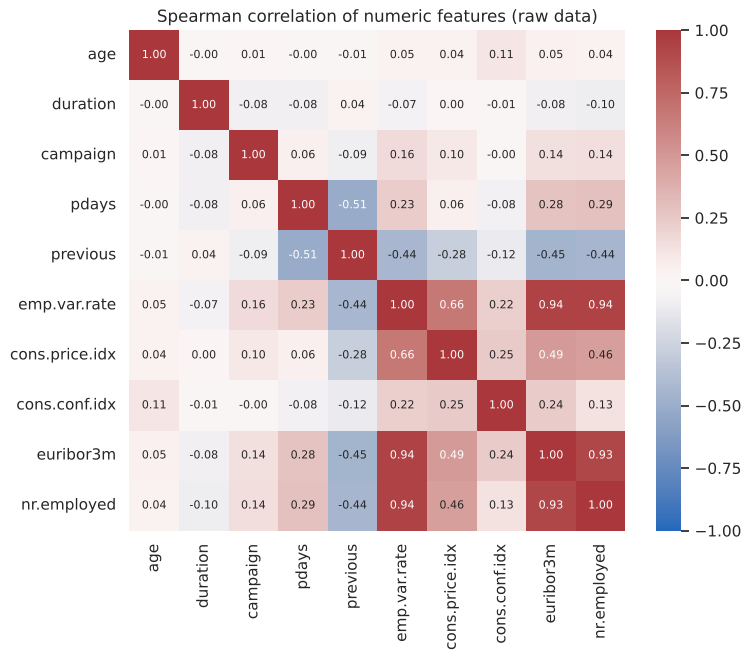

,feature_1,feature_2,spearman
59,emp.var.rate,nr.employed,0.944702
58,emp.var.rate,euribor3m,0.939915
89,euribor3m,nr.employed,0.928857


In [7]:
# Problematic predictors 2: highly correlated macro-economic indicators
corr = raw[num_raw].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Spearman correlation of numeric features (raw data)")
save_fig(fig, "q1_numeric_correlation"); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
         .rename("spearman").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
high_corr = pairs[pairs.spearman.abs() > 0.8].sort_values("spearman", key=abs, ascending=False)
display(high_corr)

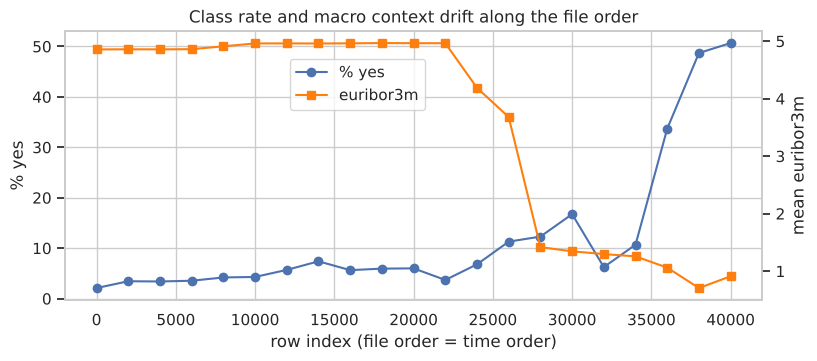

block,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
first_row,0,2000,4000,6000,8000,10000,12000,14000,16000,18000,20000,22000,24000,26000,28000,30000,32000,34000,36000,38000,40000
pct_yes,2.1,3.45,3.4,3.55,4.2,4.3,5.7,7.4,5.65,5.95,6.0,3.7,6.8,11.3,12.3,16.75,6.25,10.7,33.7,48.7,50.67
euribor3m,4.86,4.86,4.86,4.86,4.91,4.96,4.96,4.96,4.96,4.97,4.96,4.96,4.19,3.68,1.42,1.35,1.3,1.26,1.06,0.71,0.91
first_month,may,may,may,may,jun,jun,jun,jul,jul,jul,aug,aug,oct,nov,apr,apr,may,may,may,sep,jun


In [8]:
# Problematic aspect 3: rows are in chronological order (May 2008 – Nov 2010).
# Positive rate and a macro indicator over row position show strong drift.
block = np.arange(len(raw)) // 2000
drift = raw.assign(y01=y01, block=block).groupby("block").agg(
    first_row=("y01", lambda s: s.index.min()), pct_yes=("y01", lambda s: 100 * s.mean()),
    euribor3m=("euribor3m", "mean"), first_month=("month", "first"))
fig, ax1 = plt.subplots(figsize=(9, 3.5))
ax1.plot(drift.first_row, drift.pct_yes, marker="o", label="% yes")
ax1.set_xlabel("row index (file order = time order)"); ax1.set_ylabel("% yes")
ax2 = ax1.twinx(); ax2.plot(drift.first_row, drift.euribor3m, color="tab:orange", marker="s", label="euribor3m")
ax2.set_ylabel("mean euribor3m"); ax2.grid(False)
fig.legend(loc="upper center", bbox_to_anchor=(0.45, 0.82)); ax1.set_title("Class rate and macro context drift along the file order")
save_fig(fig, "q1_temporal_drift"); plt.show()
display(drift.round(2).T)

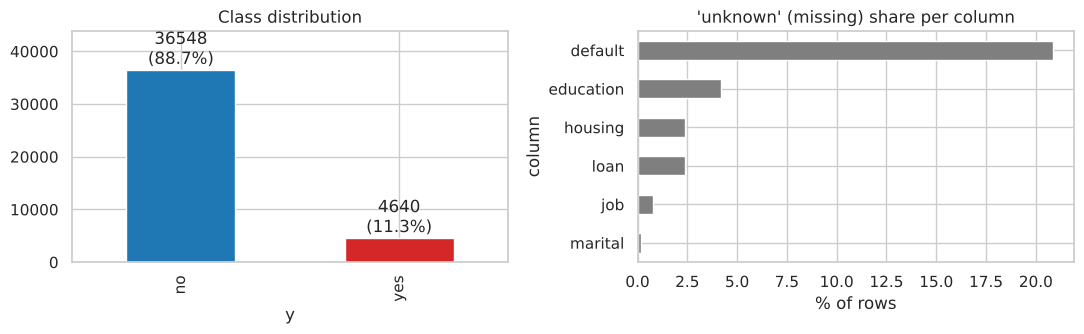

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
cls["count"].plot.bar(ax=axes[0], color=["tab:blue", "tab:red"]); axes[0].set_title("Class distribution")
for i, v in enumerate(cls["count"]): axes[0].text(i, v, f"{v}\n({cls['percent'].iloc[i]:.1f}%)", ha="center", va="bottom")
axes[0].set_ylim(0, cls["count"].max() * 1.2); axes[0].set_xlabel("y")
audit.loc[audit.pct_unknown > 0, "pct_unknown"].sort_values().plot.barh(ax=axes[1], color="tab:gray")
axes[1].set_title("'unknown' (missing) share per column"); axes[1].set_xlabel("% of rows")
plt.tight_layout(); save_fig(fig, "q1_class_and_missing"); plt.show()

### Dataset audit table (deliverable for 1(e))

In [10]:
notes = {
    "age": "right tail (IQR outliers); plausible values",
    "job": "'unknown' = missing", "marital": "'unknown' = missing",
    "education": "'unknown' = missing; 'illiterate' very rare",
    "default": "'unknown' 20.9%; 'yes' only 3 rows -> almost no information",
    "housing": "'unknown' = missing; same rows as loan",
    "loan": "'unknown' = missing; same rows as housing",
    "contact": "", "month": "no Jan/Feb; encodes time", "day_of_week": "",
    "duration": "TARGET LEAKAGE: known only after the call; duration=0 => y=no",
    "campaign": "heavy right tail (max 56)",
    "pdays": "999 = sentinel 'never contacted' (96%); not a number of days",
    "previous": "", "poutcome": "'nonexistent' consistent with previous==0",
    "emp.var.rate": "macro indicator; rho>0.9 with euribor3m, nr.employed",
    "cons.price.idx": "macro indicator", "cons.conf.idx": "macro indicator",
    "euribor3m": "macro indicator; rho>0.9 with emp.var.rate, nr.employed",
    "nr.employed": "macro indicator; rho>0.9 with emp.var.rate, euribor3m",
    "y": "imbalanced: 11.3% yes",
}
audit_table = audit[["type", "n_unique", "n_unknown", "pct_unknown", "min", "median", "max", "n_IQR_outliers"]].copy()
audit_table["note"] = pd.Series(notes)
save_table(audit_table, "q1_dataset_audit", float_format="%.2f")
save_table(anomalies, "q1_anomaly_checks")
save_table(high_corr, "q1_high_correlation_pairs", index=False, float_format="%.3f")
audit_table

,type,n_unique,n_unknown,pct_unknown,min,median,max,n_IQR_outliers,note
column,,,,,,,,,
age,numeric,78,0,0.000000,17.000,38.000,98.000,469.0,right tail (IQR outliers); plausible values
job,categorical,12,330,0.801204,NaN,NaN,NaN,NaN,'unknown' = missing
marital,categorical,4,80,0.194231,NaN,NaN,NaN,NaN,'unknown' = missing
education,categorical,8,1731,4.202680,NaN,NaN,NaN,NaN,'unknown' = missing; 'illiterate' very rare
default,categorical,3,8597,20.872584,NaN,NaN,NaN,NaN,'unknown' 20.9%; 'yes' only 3 rows -> almost n...
housing,categorical,3,990,2.403613,NaN,NaN,NaN,NaN,'unknown' = missing; same rows as loan
loan,categorical,3,990,2.403613,NaN,NaN,NaN,NaN,'unknown' = missing; same rows as housing
contact,categorical,2,0,0.000000,NaN,NaN,NaN,NaN,
month,categorical,10,0,0.000000,NaN,NaN,NaN,NaN,no Jan/Feb; encodes time


**Cleaning decisions applied before splitting** (`src/data.py::clean_bank`). They are row-wise and use no statistics of other rows or of the target, so they cannot leak information:

1. Drop the 12 exact duplicate rows, so the same record cannot end up in both train and test.
2. Recode `"unknown"` as missing (NaN). It is imputed later inside the pipeline.
3. Recode `pdays == 999` as NaN and add a binary indicator `contacted_before`.
4. Exclude `duration` from every realistic model. It is used only in the leakage demonstration in 1(d).
5. Encode the target as `y = 1` for "yes".

In [11]:
df = clean_bank(raw)
X, y = bank_xy(df)                      # without duration
X_dur, _ = bank_xy(df, include_duration=True)
print("After cleaning:", df.shape, "| features used:", X.shape[1], "| positives:", int(y.sum()), f"({100*y.mean():.2f}%)")
print("Missing values per feature after recoding:")
display(X.isna().sum()[lambda s: s > 0].rename("n_missing").to_frame().T)

After cleaning: (41176, 22) | features used: 20 | positives: 4639 (11.27%)
Missing values per feature after recoding:


,pdays,job,marital,education,default,housing,loan
n_missing,39661,330,80,1730,8596,990,990


## 1(b) Partitioning: stratified vs. ordinary random sampling

Protocol: **60 % train / 20 % validation / 20 % test**. The test set is split off first. Model selection uses the training set (5-fold stratified CV) and the validation set. The test set is used only once, in Q5(e).

In [12]:
X_train, X_val, X_test, y_train, y_val, y_test = train_val_test_split(X, y, stratify=True, seed=SEED)
part = pd.DataFrame({
    "n_rows": [len(y_train), len(y_val), len(y_test), len(y)],
    "n_yes": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum()), int(y.sum())],
}, index=["train", "validation", "test", "total"])
part["n_no"] = part.n_rows - part.n_yes
part["pct_yes"] = 100 * part.n_yes / part.n_rows
part["pct_of_total"] = 100 * part.n_rows / len(y)
save_table(part, "q1_partition_sizes", float_format="%.3f")
part

,n_rows,n_yes,n_no,pct_yes,pct_of_total
train,24705,2783,21922,11.264926,59.998543
validation,8235,928,7307,11.268974,19.999514
test,8236,928,7308,11.267606,20.001943
total,41176,4639,36537,11.266272,100.000000


In [13]:
# Class-proportion deviation |p_partition - p_full| (percentage points) over many seeds
def deviations(X_, y_, stratify, seeds):
    out = []
    p = y_.mean()
    for s in seeds:
        _, _, _, ytr, yva, yte = train_val_test_split(X_, y_, stratify=stratify, seed=s)
        out.append({"seed": s, "train": 100 * abs(ytr.mean() - p),
                    "validation": 100 * abs(yva.mean() - p), "test": 100 * abs(yte.mean() - p)})
    return pd.DataFrame(out)

seeds = range(500)
rng = np.random.default_rng(SEED)
small_idx = rng.choice(len(y), size=500, replace=False)       # small-sample scenario (n = 500)
scen = {"full data (n=%d)" % len(y): (X, y), "subsample (n=500)": (X.iloc[small_idx], y.iloc[small_idx])}

dev_rows, dev_long = [], []
for scen_name, (Xs, ys) in scen.items():
    for strat in (True, False):
        d = deviations(Xs, ys, strat, seeds)
        method = "stratified" if strat else "random"
        for p in ("train", "validation", "test"):
            dev_rows.append({"scenario": scen_name, "method": method, "partition": p,
                             "mean_dev_pp": d[p].mean(), "max_dev_pp": d[p].max(),
                             "dev_at_SEED_pp": d.loc[d.seed == SEED, p].item()})
            dev_long.append(d[[p]].rename(columns={p: "dev"}).assign(scenario=scen_name, method=method, partition=p))
dev_summary = pd.DataFrame(dev_rows).set_index(["scenario", "method", "partition"])
save_table(dev_summary, "q1_stratification_deviation", float_format="%.3f")
dev_summary

mean_dev_pp  max_dev_pp  dev_at_SEED_pp
scenario            method     partition                                          
full data (n=41176) stratified train          0.001345    0.001345        0.001345
                               validation     0.002702    0.002702        0.002702
                               test           0.001334    0.001334        0.001334
                    random     train          0.097942    0.399383        0.114683
                               validation     0.238640    1.119885        0.179447
                               test           0.256335    0.875545        0.523432
subsample (n=500)   stratified train          0.000000    0.000000        0.000000
                               validation     0.000000    0.000000        0.000000
                               test           0.000000    0.000000        0.000000
                    random     train          0.832000    3.000000        1.000000
                               validation     2.130000   10.000000        4.000000
                               test           2.118000   10.000000        1.000000

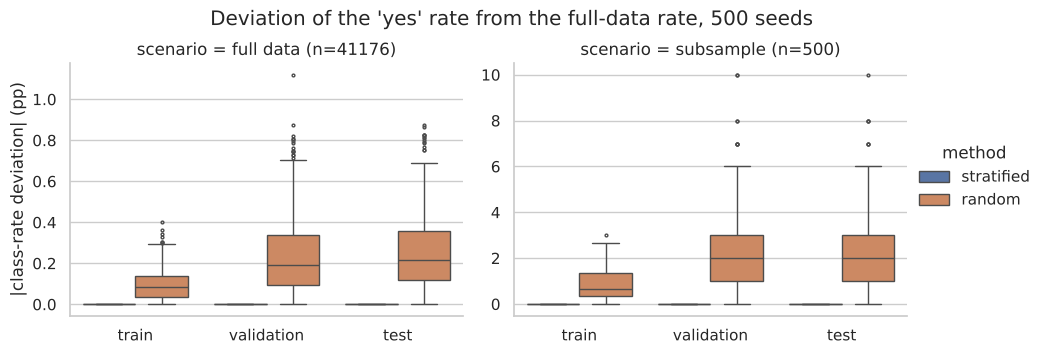

In [14]:
dev_long = pd.concat(dev_long)
g = sns.catplot(data=dev_long, x="partition", y="dev", hue="method", col="scenario", kind="box",
                sharey=False, height=3.6, aspect=1.3, fliersize=2)
g.set_axis_labels("", "|class-rate deviation| (pp)")
g.figure.suptitle("Deviation of the 'yes' rate from the full-data rate, 500 seeds", y=1.04)
save_fig(g.figure, "q1_stratification_deviation"); plt.show()

In [15]:
# Where stratification on y does NOT help
# (i) a rare *feature* category is not protected: default == 'yes' has only 3 rows
for name, Xp in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    print(f"default=='yes' in {name:10s}: {int((Xp['default'] == 'yes').sum())}")

# (ii) a class with a single member cannot be stratified at all
from sklearn.model_selection import train_test_split
y_tiny = pd.Series([0] * 9 + [1])
try:
    train_test_split(np.arange(10), y_tiny, test_size=0.3, stratify=y_tiny, random_state=SEED)
except ValueError as e:
    print("\nStratification error with a 1-member class:", e)

# (iii) temporal order: both methods mix 2008 and 2010 rows into every partition
pos = pd.Series(np.arange(len(y)), index=y.index)
print("\nMean row position (proxy for time) per partition:",
      {n: int(pos[p.index].mean()) for n, p in [("train", y_train), ("val", y_val), ("test", y_test)]})

default=='yes' in train     : 2
default=='yes' in validation: 0
default=='yes' in test      : 1

Stratification error with a 1-member class: The least populated classes in y have only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2. Classes with too few members are: [1]

Mean row position (proxy for time) per partition: {'train': 20576, 'val': 20722, 'test': 20484}


## 1(c) Leakage-safe preprocessing pipeline

`src/preprocessing.py::make_bank_preprocessor` returns an **unfitted** `ColumnTransformer`. It is always placed inside a `Pipeline` together with the model, so in cross-validation it is refitted on every training fold.

| Column group | Steps (`kind="linear"`) |
|---|---|
| numeric (9 columns) | median imputation (`pdays` sentinel → NaN) + missing indicator → `StandardScaler` |
| `contacted_before` | passthrough (0/1) |
| categorical (10 columns) | constant imputation `"missing"` → `OneHotEncoder(handle_unknown="ignore")` |

No text features are present, so no tokenization or vectorization is needed.

In [16]:
pre = make_bank_preprocessor("linear")
Z_train = pre.fit_transform(X_train)          # fitted on TRAINING rows only
Z_val = pre.transform(X_val)
names = pre.get_feature_names_out()
print("Input columns:", X_train.shape[1], "-> transformed columns:", Z_train.shape[1])
print("NaN after transform  train:", np.isnan(Z_train).sum(), " val:", np.isnan(Z_val).sum())

num_idx = [i for i, n in enumerate(names) if n in BANK_NUMERIC]
chk = pd.DataFrame({"train_mean": Z_train[:, num_idx].mean(0), "train_std": Z_train[:, num_idx].std(0),
                    "val_mean": Z_val[:, num_idx].mean(0), "val_std": Z_val[:, num_idx].std(0)},
                   index=names[num_idx])
print("\nScaled numerics: exactly (0, 1) on train, only approximately on validation -> parameters come from train only")
display(chk.round(3))

imp = pre.named_transformers_["num"].named_steps["impute"]
print("Imputation medians learned from train:", dict(zip(BANK_NUMERIC, imp.statistics_.round(3))))

Input columns: 20 -> transformed columns: 64
NaN after transform  train: 0  val: 0

Scaled numerics: exactly (0, 1) on train, only approximately on validation -> parameters come from train only


,train_mean,train_std,val_mean,val_std
age,0.0,1.0,-0.002,0.996
campaign,0.0,1.0,0.003,1.001
pdays,-0.0,1.0,-0.014,0.934
previous,0.0,1.0,0.030,1.039
emp.var.rate,-0.0,1.0,-0.010,0.997
cons.price.idx,-0.0,1.0,0.005,1.003
cons.conf.idx,0.0,1.0,-0.021,1.000
euribor3m,0.0,1.0,-0.012,1.002
nr.employed,0.0,1.0,-0.014,1.011


Imputation medians learned from train: {'age': np.float64(38.0), 'campaign': np.float64(2.0), 'pdays': np.float64(6.0), 'previous': np.float64(0.0), 'emp.var.rate': np.float64(1.1), 'cons.price.idx': np.float64(93.749), 'cons.conf.idx': np.float64(-41.8), 'euribor3m': np.float64(4.857), 'nr.employed': np.float64(5191.0)}


In [17]:
# Unseen category at prediction time: handled without error (all-zero one-hot block)
x_new = X_val.iloc[[0]].copy()
x_new["job"] = "astronaut"           # never seen in training
z_new = pre.transform(x_new)
job_cols = [i for i, n in enumerate(names) if n.startswith("job_")]
print("job one-hot block for an unseen category:", z_new[0, job_cols])

tree_pre = make_bank_preprocessor("tree").fit(X_train)
print("ordinal code for unseen category (tree preprocessor):",
      tree_pre.transform(x_new)[0, list(tree_pre.get_feature_names_out()).index("job")])

job one-hot block for an unseen category: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
ordinal code for unseen category (tree preprocessor): -1.0


In [18]:
family = pd.DataFrame([
    ["Logistic Regression", "median + indicator", "yes (StandardScaler)", "one-hot", "gradient/penalty depend on feature scale"],
    ["k-Nearest Neighbors", "median + indicator", "yes (essential)", "one-hot", "distances are scale dependent"],
    ["Gaussian Naive Bayes", "median + indicator", "not needed", "one-hot", "per-feature Gaussian likelihoods"],
    ["Categorical/Bernoulli NB", "constant 'missing'", "n/a (binned numerics)", "ordinal / one-hot", "needs discrete inputs"],
    ["Decision Tree / RF", "median + indicator", "no (split invariant)", "ordinal or one-hot", "monotone transforms do not change splits"],
    ["AdaBoost / Gradient Boosting", "median + indicator", "no", "ordinal or one-hot", "tree base learners"],
    ["Dummy baseline", "-", "-", "-", "ignores features"],
], columns=["model family", "numeric missingness", "scaling", "categorical encoding", "reason"]).set_index("model family")
save_table(family, "q1_transformations_by_model")
family

,numeric missingness,scaling,categorical encoding,reason
model family,,,,
Logistic Regression,median + indicator,yes (StandardScaler),one-hot,gradient/penalty depend on feature scale
k-Nearest Neighbors,median + indicator,yes (essential),one-hot,distances are scale dependent
Gaussian Naive Bayes,median + indicator,not needed,one-hot,per-feature Gaussian likelihoods
Categorical/Bernoulli NB,constant 'missing',n/a (binned numerics),ordinal / one-hot,needs discrete inputs
Decision Tree / RF,median + indicator,no (split invariant),ordinal or one-hot,monotone transforms do not change splits
AdaBoost / Gradient Boosting,median + indicator,no,ordinal or one-hot,tree base learners
Dummy baseline,-,-,-,ignores features


## 1(d) Controlled leakage demonstration

All experiments use **only the development data** (train for CV, train+validation for the hold-out check). The test set is not used.
The model, CV folds (5-fold stratified, seed fixed) and metrics are identical for every experiment. Only the procedure changes.

| ID | Procedure | Status |
|---|---|---|
| V | preprocessing + `SelectKBest` inside the pipeline, refitted per fold | **valid** |
| L1 | scaler + imputer + `SelectKBest` fitted on *all* development rows before CV / before the train–val split | **INVALID – demonstration only** |
| L2 | same as L1, with 2,000 pure-noise features added and a small sample (n = 500). This is the setting where selection leakage becomes large | **INVALID – demonstration only** (V2 is its valid counterpart) |
| L3 | valid pipeline, plus the target-leaking feature `duration` | **INVALID – demonstration only** |

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "macro_f1": "f1_macro"}
K = 20

def clf():
    return LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED)

def cv_summary(est, Xc, yc):
    r = cross_validate(est, Xc, yc, cv=CV, scoring=SCORING)
    return {f"cv_{m}": f"{r['test_'+m].mean():.4f} ± {r['test_'+m].std():.4f}" for m in SCORING} | \
           {f"_cv_{m}_mean": r["test_" + m].mean() for m in SCORING}

def holdout(model, Xtr, ytr, Xva, yva):
    model.fit(Xtr, ytr)
    p = model.predict_proba(Xva)[:, 1]
    return {"val_roc_auc": roc_auc_score(yva, p), "val_pr_auc": average_precision_score(yva, p),
            "val_macro_f1": f1_score(yva, model.predict(Xva), average="macro")}

results = {}

In [20]:
# V: valid
valid_pipe = lambda include_duration=False: Pipeline([
    ("pre", make_bank_preprocessor("linear", include_duration=include_duration)),
    ("select", SelectKBest(f_classif, k=K)), ("clf", clf())])
results["V   valid pipeline"] = cv_summary(valid_pipe(), X_train, y_train) | \
    holdout(valid_pipe(), X_train, y_train, X_val, y_val)

# L1: INVALID - preprocessing + feature selection fitted on all development rows (train + val)
X_dev = pd.concat([X_train, X_val]); y_dev = pd.concat([y_train, y_val])
leaky_front = Pipeline([("pre", make_bank_preprocessor("linear")), ("select", SelectKBest(f_classif, k=K))])
Z_dev = pd.DataFrame(leaky_front.fit_transform(X_dev, y_dev), index=X_dev.index)   # <- sees val rows and labels
results["L1  INVALID: preprocess+select on all rows"] = cv_summary(clf(), Z_dev.loc[X_train.index], y_train) | \
    holdout(clf(), Z_dev.loc[X_train.index], y_train, Z_dev.loc[X_val.index], y_val)

In [21]:
# L2 / V2: the same mistake in a high-dimensional, small-sample setting
# Controlled augmentation: 2,000 standard-normal noise columns, independent of y by construction.
N_SMALL, N_NOISE = 500, 2000
rng = np.random.default_rng(SEED)
small_tr = rng.choice(X_train.index, size=N_SMALL, replace=False)
small_va = rng.choice(X_val.index, size=N_SMALL, replace=False)
noise = lambda idx: pd.DataFrame(rng.standard_normal((len(idx), N_NOISE)), index=idx,
                                 columns=[f"noise_{i}" for i in range(N_NOISE)])
Xs_tr = pd.concat([X_train.loc[small_tr], noise(small_tr)], axis=1); ys_tr = y_train.loc[small_tr]
Xs_va = pd.concat([X_val.loc[small_va], noise(small_va)], axis=1);   ys_va = y_val.loc[small_va]

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
noise_cols = [f"noise_{i}" for i in range(N_NOISE)]
def pre_with_noise():
    base = make_bank_preprocessor("linear")
    return ColumnTransformer(base.transformers + [("noise", StandardScaler(), noise_cols)],
                             verbose_feature_names_out=False)

v2 = lambda: Pipeline([("pre", pre_with_noise()), ("select", SelectKBest(f_classif, k=K)), ("clf", clf())])
results["V2  valid pipeline, n=500 + 2000 noise cols"] = cv_summary(v2(), Xs_tr, ys_tr) | holdout(v2(), Xs_tr, ys_tr, Xs_va, ys_va)

Xs_dev = pd.concat([Xs_tr, Xs_va]); ys_dev = pd.concat([ys_tr, ys_va])
front2 = Pipeline([("pre", pre_with_noise()), ("select", SelectKBest(f_classif, k=K))])
Zs = pd.DataFrame(front2.fit_transform(Xs_dev, ys_dev), index=Xs_dev.index)       # <- INVALID
results["L2  INVALID: select on all rows, n=500 + 2000 noise"] = cv_summary(clf(), Zs.loc[small_tr], ys_tr) | \
    holdout(clf(), Zs.loc[small_tr], ys_tr, Zs.loc[small_va], ys_va)

sel_names = front2.named_steps["pre"].get_feature_names_out()[front2.named_steps["select"].get_support()]
n_noise_sel = sum(n.startswith("noise_") for n in sel_names)
print(f"L2: {n_noise_sel} of the {K} selected features are pure noise")

L2: 6 of the 20 selected features are pure noise


In [22]:
# L3: INVALID - target leakage through `duration`
X_dur_train, X_dur_val = X_dur.loc[X_train.index], X_dur.loc[X_val.index]
results["L3  INVALID: + duration (target leakage)"] = cv_summary(valid_pipe(True), X_dur_train, y_train) | \
    holdout(valid_pipe(True), X_dur_train, y_train, X_dur_val, y_val)

In [23]:
res = pd.DataFrame(results).T
shown = res[[c for c in res.columns if not c.startswith("_")]].copy()
for c in ["val_roc_auc", "val_pr_auc", "val_macro_f1"]:
    shown[c] = shown[c].astype(float).round(4)
save_table(shown, "q1_leakage_demo")
display(shown)

# Differences relative to the matching valid baseline
pairs_ = {"L1  INVALID: preprocess+select on all rows": "V   valid pipeline",
          "L2  INVALID: select on all rows, n=500 + 2000 noise": "V2  valid pipeline, n=500 + 2000 noise cols",
          "L3  INVALID: + duration (target leakage)": "V   valid pipeline"}
num = res.drop(columns=[c for c in res.columns if c.startswith("cv_")]).astype(float)
delta = pd.DataFrame({k: num.loc[k] - num.loc[v] for k, v in pairs_.items()}).T
delta.columns = [c.lstrip("_").replace("_mean", "") for c in delta.columns]
delta = delta.add_prefix("Δ ")
save_table(delta, "q1_leakage_delta")
delta.round(4)

,cv_roc_auc,cv_pr_auc,cv_macro_f1,val_roc_auc,val_pr_auc,val_macro_f1
V valid pipeline,0.7859 ± 0.0092,0.4367 ± 0.0143,0.6756 ± 0.0066,0.7977,0.4406,0.6829
L1 INVALID: preprocess+select on all rows,0.7857 ± 0.0092,0.4365 ± 0.0146,0.6756 ± 0.0066,0.7976,0.4406,0.6828
"V2 valid pipeline, n=500 + 2000 noise cols",0.6562 ± 0.0620,0.3479 ± 0.1254,0.5908 ± 0.0611,0.7069,0.3567,0.5899
"L2 INVALID: select on all rows, n=500 + 2000 noise",0.7987 ± 0.0233,0.5299 ± 0.0233,0.6372 ± 0.0261,0.7798,0.4163,0.6189
L3 INVALID: + duration (target leakage),0.9362 ± 0.0029,0.5853 ± 0.0169,0.7531 ± 0.0074,0.9335,0.5795,0.7445


,Δ cv_roc_auc,Δ cv_pr_auc,Δ cv_macro_f1,Δ val_roc_auc,Δ val_pr_auc,Δ val_macro_f1
L1 INVALID: preprocess+select on all rows,-0.0002,-0.0002,0.0000,-0.0001,-0.0000,-0.0001
"L2 INVALID: select on all rows, n=500 + 2000 noise",0.1425,0.1820,0.0464,0.0729,0.0596,0.0290
L3 INVALID: + duration (target leakage),0.1502,0.1486,0.0776,0.1358,0.1389,0.0616


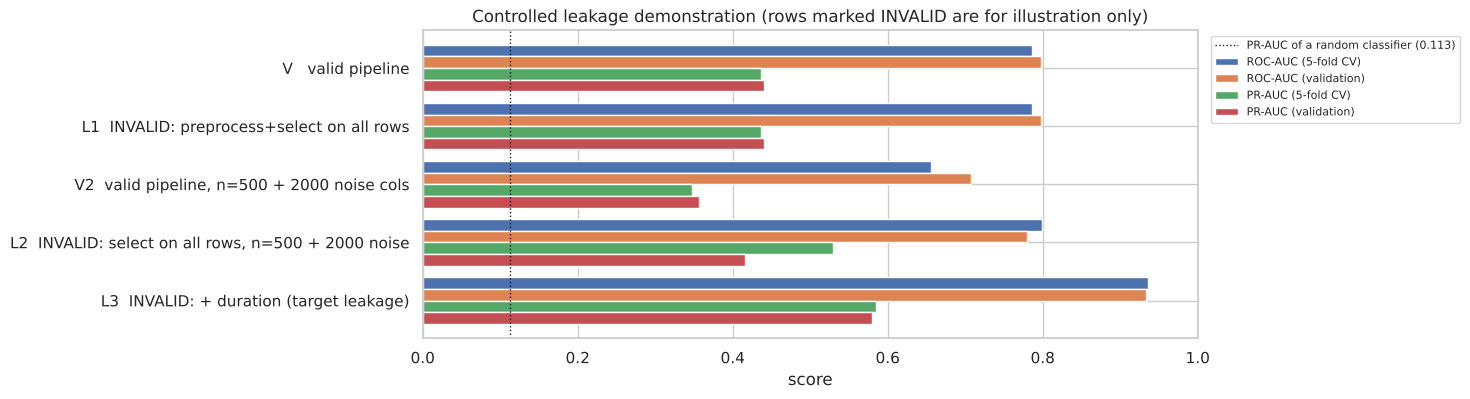

In [24]:
plot_df = num[["_cv_roc_auc_mean", "val_roc_auc", "_cv_pr_auc_mean", "val_pr_auc"]].rename(columns={
    "_cv_roc_auc_mean": "ROC-AUC (5-fold CV)", "val_roc_auc": "ROC-AUC (validation)",
    "_cv_pr_auc_mean": "PR-AUC (5-fold CV)", "val_pr_auc": "PR-AUC (validation)"})
fig, ax = plt.subplots(figsize=(10, 4))
plot_df.plot.barh(ax=ax, width=0.8)
ax.axvline(y.mean(), color="k", ls=":", lw=1, label=f"PR-AUC of a random classifier ({y.mean():.3f})")
ax.set_xlim(0, 1); ax.invert_yaxis(); ax.set_xlabel("score")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.set_title("Controlled leakage demonstration (rows marked INVALID are for illustration only)")
save_fig(fig, "q1_leakage_demo"); plt.show()

> **TODO (öğrenci yorumu):** Interpret the differences in the Δ table. Why does L1 change little and L2 change a lot? Why would L3 not reproduce in deployment? Why can a better CV score not be trusted?

## 1(e) Experimental-protocol diagram

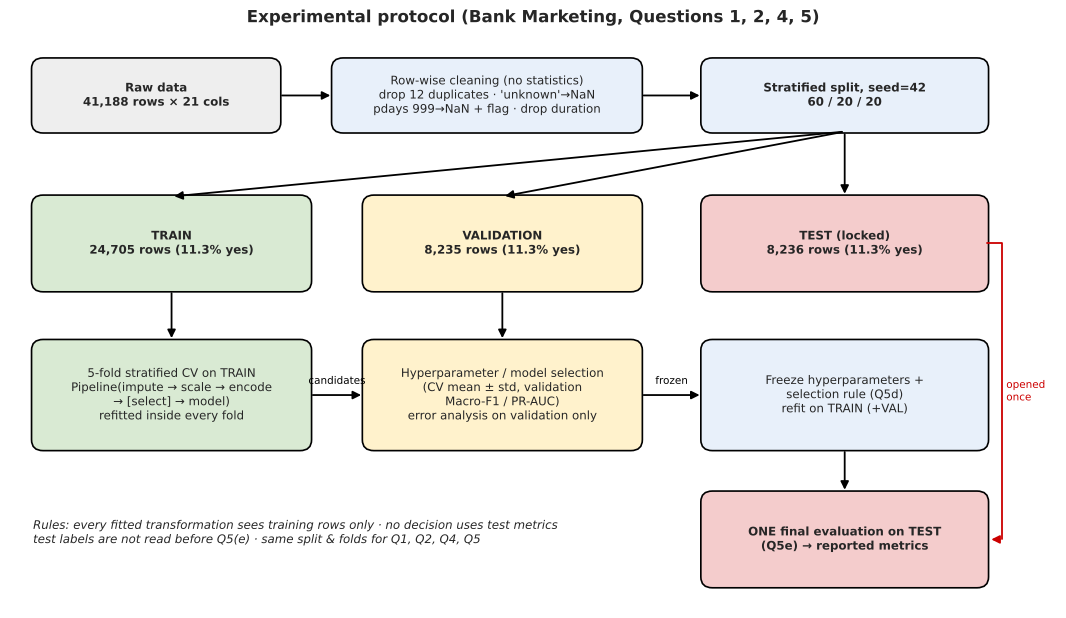

In [25]:
from matplotlib.patches import FancyBboxPatch

def box(ax, x, y, w, h, text, fc, ec="black", fs=8.5, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15", fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, weight="bold" if bold else "normal", wrap=True)

def arrow(ax, x1, y1, x2, y2, text=None, color="black"):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color=color, lw=1.3))
    if text: ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.12, text, fontsize=7.5, color=color, ha="center", va="bottom")

fig, ax = plt.subplots(figsize=(13.5, 7.5)); ax.set_xlim(0, 13.6); ax.set_ylim(0, 8); ax.axis("off")
box(ax, 0.3, 6.6, 3.2, 1.0, f"Raw data\n{raw.shape[0]:,} rows × {raw.shape[1]} cols", "#eeeeee", bold=True)
box(ax, 4.2, 6.6, 4.0, 1.0, "Row-wise cleaning (no statistics)\ndrop 12 duplicates · 'unknown'→NaN\npdays 999→NaN + flag · drop duration", "#e8f0fa")
arrow(ax, 3.5, 7.1, 4.2, 7.1)
box(ax, 9.0, 6.6, 3.7, 1.0, f"Stratified split, seed={SEED}\n60 / 20 / 20", "#e8f0fa", bold=True)
arrow(ax, 8.2, 7.1, 9.0, 7.1)

box(ax, 0.3, 4.4, 3.6, 1.3, f"TRAIN\n{len(y_train):,} rows ({100*y_train.mean():.1f}% yes)", "#d9ead3", bold=True)
box(ax, 4.6, 4.4, 3.6, 1.3, f"VALIDATION\n{len(y_val):,} rows ({100*y_val.mean():.1f}% yes)", "#fff2cc", bold=True)
box(ax, 9.0, 4.4, 3.7, 1.3, f"TEST (locked)\n{len(y_test):,} rows ({100*y_test.mean():.1f}% yes)", "#f4cccc", bold=True)
for xx in (2.1, 6.4, 10.85): arrow(ax, 10.85, 6.6, xx, 5.7)

box(ax, 0.3, 2.2, 3.6, 1.5, "5-fold stratified CV on TRAIN\nPipeline(impute → scale → encode\n→ [select] → model)\nrefitted inside every fold", "#d9ead3")
arrow(ax, 2.1, 4.4, 2.1, 3.7)
box(ax, 4.6, 2.2, 3.6, 1.5, "Hyperparameter / model selection\n(CV mean ± std, validation\nMacro-F1 / PR-AUC)\nerror analysis on validation only", "#fff2cc")
arrow(ax, 3.9, 2.95, 4.6, 2.95, "candidates")
arrow(ax, 6.4, 4.4, 6.4, 3.7)
box(ax, 9.0, 2.2, 3.7, 1.5, "Freeze hyperparameters +\nselection rule (Q5d)\nrefit on TRAIN (+VAL)", "#e8f0fa")
arrow(ax, 8.2, 2.95, 9.0, 2.95, "frozen")
box(ax, 9.0, 0.3, 3.7, 1.3, "ONE final evaluation on TEST\n(Q5e) → reported metrics", "#f4cccc", bold=True)
arrow(ax, 10.85, 2.2, 10.85, 1.6)
ax.plot([12.7, 12.9, 12.9], [5.05, 5.05, 0.95], color="#cc0000", lw=1.3)
arrow(ax, 12.9, 0.95, 12.72, 0.95, color="#cc0000")
ax.text(12.95, 3.0, "opened\nonce", fontsize=7.5, color="#cc0000", va="center")
ax.text(0.3, 0.9, "Rules: every fitted transformation sees training rows only · no decision uses test metrics\n"
                  "test labels are not read before Q5(e) · same split & folds for Q1, Q2, Q4, Q5",
        fontsize=8.5, style="italic")
ax.set_title("Experimental protocol (Bank Marketing, Questions 1, 2, 4, 5)", fontsize=12, weight="bold")
save_fig(fig, "q1_protocol_diagram"); plt.show()

> **TODO (öğrenci yorumu):** Explain at least three failure modes that could invalidate results even when the code runs without errors. Use the evidence above: temporal drift, duplicates, `duration`, rare categories, `pdays` sentinel, selection by test metrics, etc.

In [26]:
print("Saved tables :", sorted(p.name for p in TABLES.glob("q1_*.csv")))
print("Saved figures:", sorted(p.name for p in FIGURES.glob("q1_*.png")))

Saved tables : ['q1_anomaly_checks.csv', 'q1_dataset_audit.csv', 'q1_high_correlation_pairs.csv', 'q1_leakage_delta.csv', 'q1_leakage_demo.csv', 'q1_partition_sizes.csv', 'q1_stratification_deviation.csv', 'q1_transformations_by_model.csv']
Saved figures: ['q1_class_and_missing.png', 'q1_leakage_demo.png', 'q1_numeric_correlation.png', 'q1_protocol_diagram.png', 'q1_stratification_deviation.png', 'q1_temporal_drift.png']
